<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/video5_4_errores_yolo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ⚠️ 4 errores que arruinan tu modelo YOLO (y cómo evitarlos)
**Laboratorio de Códigos** · Ultralytics + COCO128

Cada sección es un error: **cómo detectarlo** con código y **cómo arreglarlo**. Activa GPU T4.

In [ ]:
!pip install -q ultralytics

In [ ]:
import glob, os, shutil, random
from collections import Counter
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from ultralytics import YOLO
from ultralytics.data.utils import check_det_dataset

data = check_det_dataset("coco128.yaml")          # descarga COCO128 (128 imágenes)
dir_imgs = str(data["train"])
dir_lbls = dir_imgs.replace(os.sep + "images" + os.sep, os.sep + "labels" + os.sep)
nombres = data["names"]
archivos = sorted(glob.glob(os.path.join(dir_lbls, "*.txt")))
print(len(archivos), "archivos de etiquetas")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

WARNING ⚠️ Dataset 'coco128.yaml' images not found, missing path '/content/datasets/coco128/images/train2017'
Unzipping /content/datasets/coco128.zip to /content/datasets/coco128...: 100% ━━━━━━━━━━━━ 263/263 695.3files/s 0.4s
Dataset download success ✅ (1.2s), saved to /content/datasets

128 archivos de etiquetas


## ❌ Error 1: dataset desbalanceado
Si una clase tiene cientos de ejemplos y otra solo 2, el modelo aprende la primera y casi ignora la segunda.

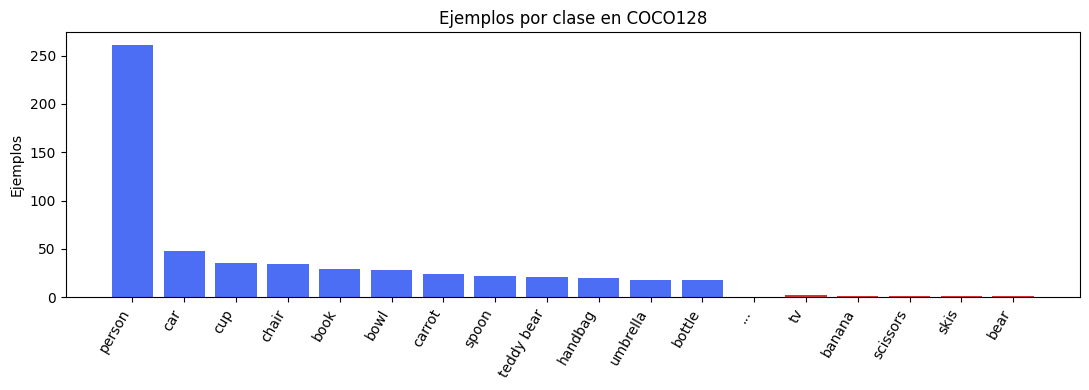

La clase más común tiene 261 ejemplos; la menos común, 1.


In [ ]:
conteo = Counter(int(l.split()[0]) for f in archivos for l in open(f) if l.strip())
top = conteo.most_common()
etq = [nombres[c] for c, _ in top[:12]] + ["..."] + [nombres[c] for c, _ in top[-5:]]
val = [n for _, n in top[:12]] + [0] + [n for _, n in top[-5:]]

plt.figure(figsize=(11, 4))
plt.bar(etq, val, color=["#e03131" if v < 10 else "#4c6ef5" for v in val])
plt.xticks(rotation=60, ha="right"); plt.ylabel("Ejemplos"); plt.title("Ejemplos por clase en COCO128")
plt.tight_layout(); plt.show()
print(f"La clase más común tiene {top[0][1]} ejemplos; la menos común, {top[-1][1]}.")

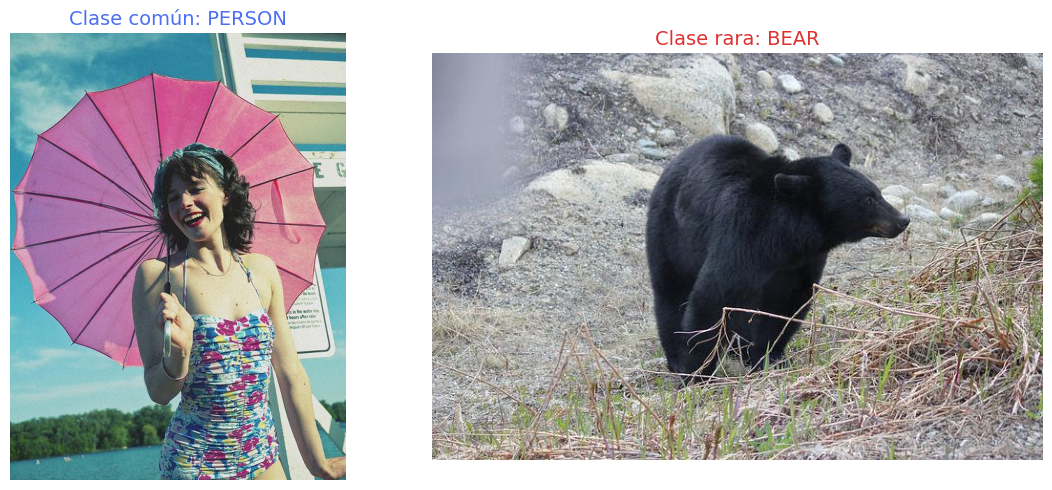

In [ ]:
# Busquemos ejemplos visuales de la clase más común y la más rara
clase_max = top[0][0]  # person
clase_min = top[-1][0] # bear

img_max, img_min = None, None
for f in archivos:
    clases_en_archivo = [int(l.split()[0]) for l in open(f) if l.strip()]
    ruta_img = f.replace(dir_lbls, dir_imgs).replace(".txt", ".jpg")

    if clase_max in clases_en_archivo and img_max is None:
        img_max = cv2.imread(ruta_img)[:, :, ::-1]
    if clase_min in clases_en_archivo and img_min is None:
        img_min = cv2.imread(ruta_img)[:, :, ::-1]
    if img_max is not None and img_min is not None:
        break

# Dibujar los ejemplos encontrados
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
if img_max is not None:
    ax[0].imshow(img_max)
    ax[0].set_title(f"Clase común: {nombres[clase_max].upper()}", fontsize=14, color="#4c6ef5")
    ax[0].axis("off")
if img_min is not None:
    ax[1].imshow(img_min)
    ax[1].set_title(f"Clase rara: {nombres[clase_min].upper()}", fontsize=14, color="#e03131")
    ax[1].axis("off")

plt.tight_layout()
plt.show()

**Arreglo:** cuenta tus clases *antes* de entrenar. Junta más ejemplos de las clases raras (meta: que ninguna tenga menos de ~10% de la mayor), une clases parecidas o quita las que no necesitas.

## ❌ Error 2: etiquetas mal hechas
Coordenadas fuera de la imagen, cajas de tamaño cero, duplicadas o clases que no existen. YOLO entrena igual… y aprende basura.

In [ ]:
def revisar_etiquetas(archivos, n_clases):
    problemas = []
    for f in archivos:
        vistas = set()
        for i, linea in enumerate(open(f), 1):
            p = linea.split()
            if not p:
                continue
            if len(p) != 5:
                problemas.append((f, i, "no tiene 5 valores")); continue
            c, x, y, w, h = int(float(p[0])), *map(float, p[1:])
            if not 0 <= c < n_clases:            problemas.append((f, i, f"clase {c} no existe"))
            if w <= 0 or h <= 0:                 problemas.append((f, i, "caja de tamaño cero"))
            if x - w/2 < -0.01 or x + w/2 > 1.01 or y - h/2 < -0.01 or y + h/2 > 1.01:
                problemas.append((f, i, "caja fuera de la imagen"))
            clave = tuple(round(v, 3) for v in (c, x, y, w, h))
            if clave in vistas:                  problemas.append((f, i, "caja duplicada"))
            vistas.add(clave)
    return problemas

print("COCO128 original:", len(revisar_etiquetas(archivos, len(nombres))), "problemas")

# Simulamos errores típicos en una copia para ver al revisor en acción
os.makedirs("etiquetas_rotas", exist_ok=True)
rotas = []
for f, error in zip(archivos[:4], ["0 1.30 0.5 0.2 0.2\n", "0 0.5 0.5 0 0.1\n", "999 0.5 0.5 0.1 0.1\n", None]):
    destino = os.path.join("etiquetas_rotas", os.path.basename(f))
    lineas = open(f).readlines()
    lineas.append(error if error else lineas[0])          # el último: duplicada
    open(destino, "w").writelines(lineas); rotas.append(destino)

for f, linea, motivo in revisar_etiquetas(rotas, len(nombres)):
    print(f"{os.path.basename(f)}  línea {linea}: {motivo}")

COCO128 original: 0 problemas
000000000009.txt  línea 9: caja fuera de la imagen
000000000025.txt  línea 3: caja de tamaño cero
000000000030.txt  línea 3: clase 999 no existe
000000000034.txt  línea 2: caja duplicada


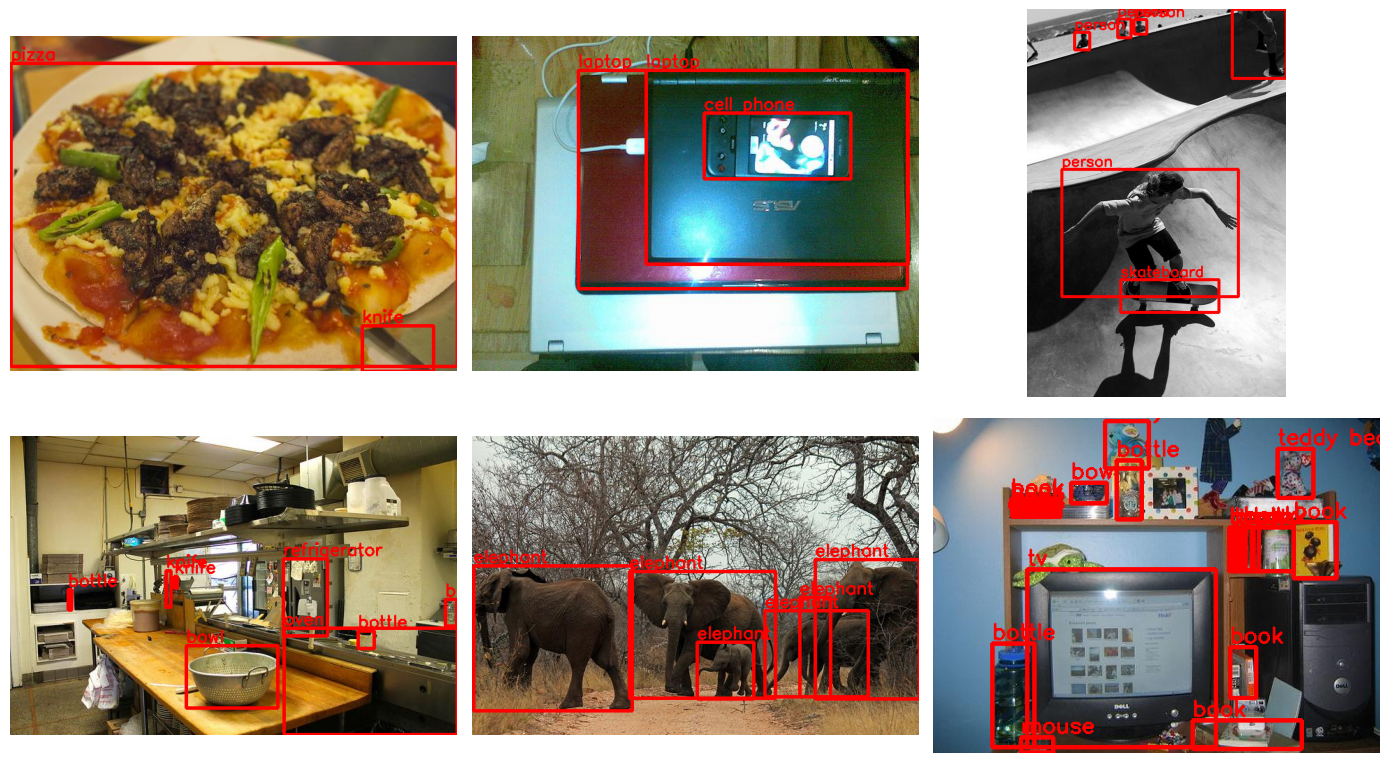

In [ ]:
# Y siempre: ver las etiquetas dibujadas sobre las imágenes
fig, ax = plt.subplots(2, 3, figsize=(14, 8))
for a, f in zip(ax.flat, random.sample(archivos, 6)):
    img = cv2.imread(f.replace(dir_lbls, dir_imgs).replace(".txt", ".jpg"))[:, :, ::-1].copy()
    H, W = img.shape[:2]
    for l in open(f):
        c, x, y, w, h = map(float, l.split())
        x1, y1, x2, y2 = int((x - w/2) * W), int((y - h/2) * H), int((x + w/2) * W), int((y + h/2) * H)
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 3)
        cv2.putText(img, nombres[int(c)], (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)
    a.imshow(img); a.axis("off")
plt.tight_layout(); plt.show()

**Arreglo:** corre el revisor antes de cada entrenamiento y mira al menos 20 imágenes con sus cajas dibujadas.

## ❌ Error 3: objetos muy pequeños
YOLO reduce la imagen a 640 px. Un objeto de 20 px en la foto original queda en unos pocos píxeles y desaparece.

Tamaño del mosaico: 3240 x 4320


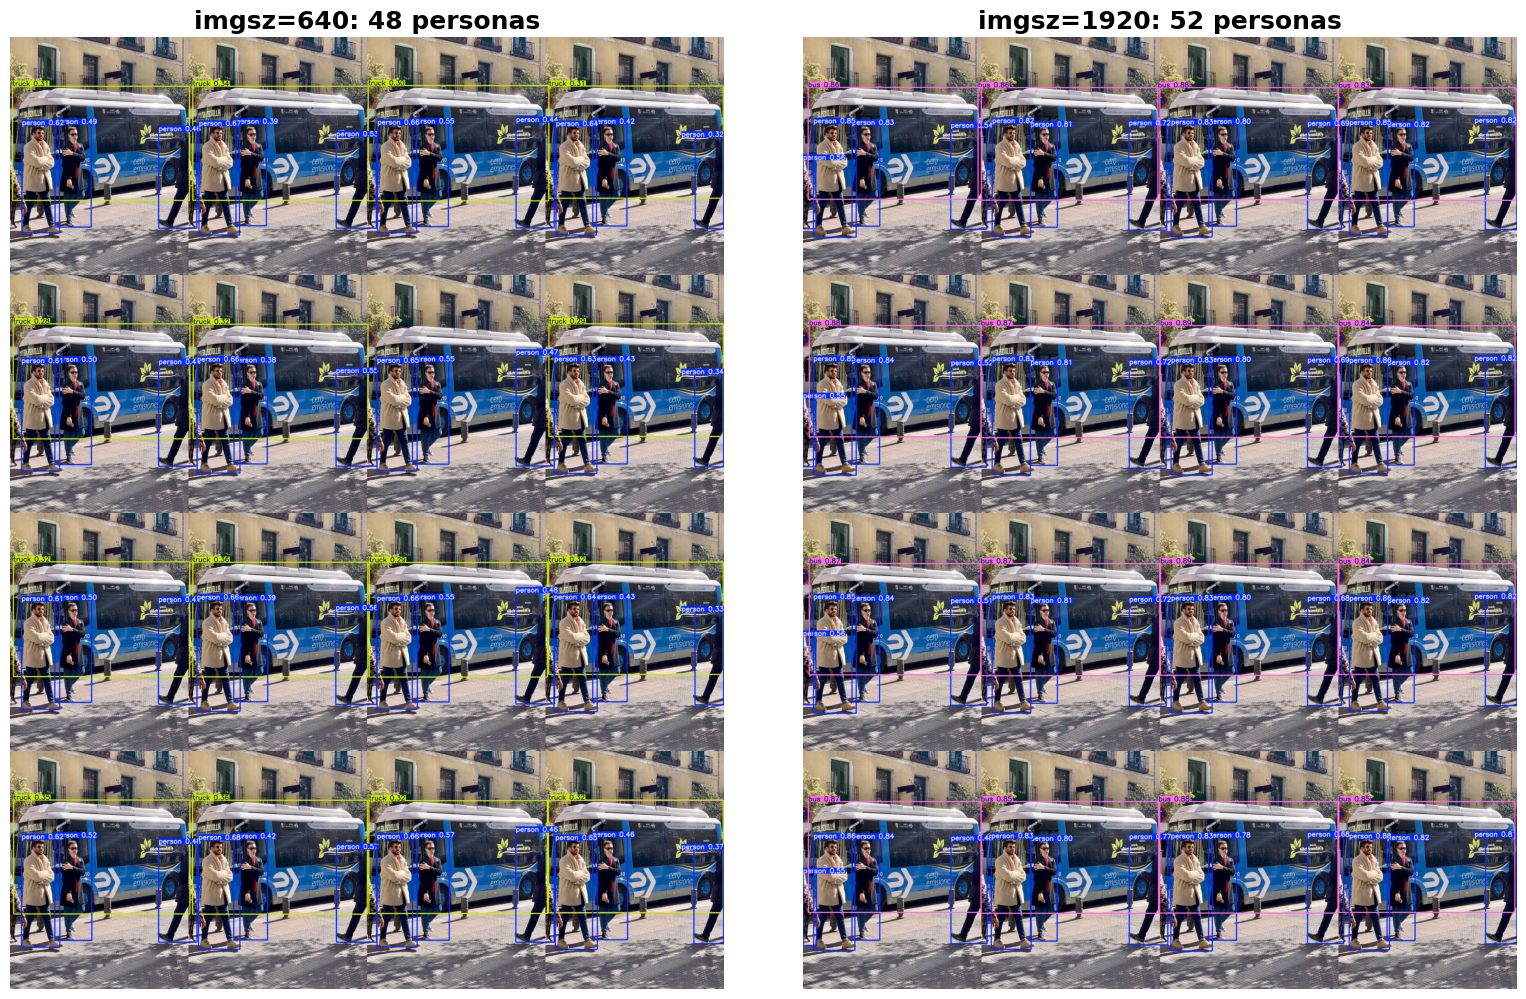

In [ ]:
# Hacemos una imagen de 4x4 copias de la foto del autobús: personas diminutas
import urllib.request
urllib.request.urlretrieve("https://ultralytics.com/images/bus.jpg", "bus.jpg")
bus = cv2.imread("bus.jpg")
mosaico = np.vstack([np.hstack([bus] * 4)] * 4)
cv2.imwrite("mosaico.jpg", mosaico)
print("Tamaño del mosaico:", mosaico.shape[1], "x", mosaico.shape[0])

modelo = YOLO("yolo26n.pt")        # o "yolo11n.pt"
fig, ax = plt.subplots(1, 2, figsize=(16, 10))
for a, tam in zip(ax, (640, 1920)):
    r = modelo("mosaico.jpg", imgsz=tam, verbose=False)[0]
    personas = int((r.boxes.cls == 0).sum())
    a.imshow(r.plot(line_width=3)[:, :, ::-1]); a.axis("off")
    a.set_title(f"imgsz={tam}: {personas} personas", fontsize=18, fontweight="bold")
plt.tight_layout(); plt.show()

In [ ]:
# ¿Qué tanto pasa en TU dataset? % de cajas que quedan menores a 16 px al entrenar a 640
lados = []
for f in archivos:
    ruta_img = f.replace(dir_lbls, dir_imgs).replace(".txt", ".jpg")
    img = cv2.imread(ruta_img)
    if img is None:
        # Intentamos con .jpeg por si acaso
        ruta_img = f.replace(dir_lbls, dir_imgs).replace(".txt", ".jpeg")
        img = cv2.imread(ruta_img)

    if img is None:
        continue  # Si sigue siendo None, omitimos esta imagen

    escala = 640 / max(img.shape[:2])
    for l in open(f):
        _, _, _, w, h = map(float, l.split())
        lados.append(min(w * img.shape[1], h * img.shape[0]) * escala)
lados = np.array(lados)
print(f"{ (lados < 16).mean()*100:.1f}% de las cajas miden menos de 16 px a imgsz=640")

23.5% de las cajas miden menos de 16 px a imgsz=640


**Arreglo:** entrena y predice con `imgsz=1280`, usa SAHI para dividir la imagen en cuadros, o acerca la cámara.

## ❌ Error 4: sobreentrenamiento
Entrenamos **desde cero** con solo 4 imágenes (COCO8) muchas épocas: el modelo memoriza el entrenamiento y falla en validación.

Ultralytics 8.4.217 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=sobreentrenado, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto

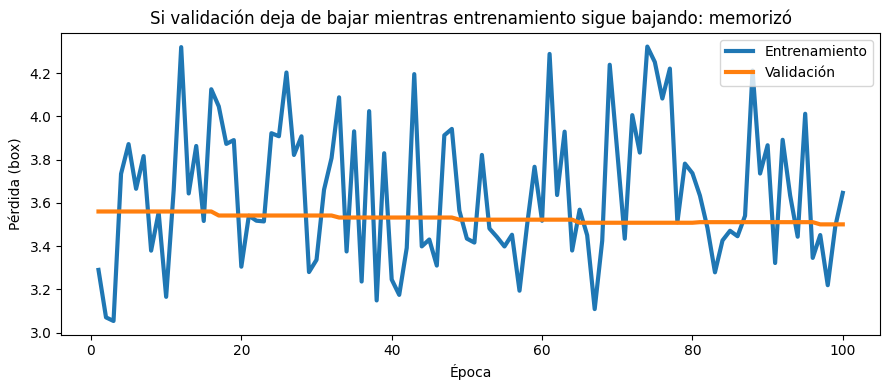

In [ ]:
chico = YOLO("yolo26n.yaml")       # desde cero; o "yolo11n.yaml"
chico.train(data="coco8.yaml", epochs=100, imgsz=640, batch=4, patience=0, plots=False,
            name="sobreentrenado", verbose=False)

res = pd.read_csv(os.path.join(chico.trainer.save_dir, "results.csv"))
res.columns = res.columns.str.strip()
plt.figure(figsize=(9, 4))
plt.plot(res["epoch"], res["train/box_loss"], label="Entrenamiento", lw=3)
plt.plot(res["epoch"], res["val/box_loss"], label="Validación", lw=3)
plt.xlabel("Época"); plt.ylabel("Pérdida (box)"); plt.legend()
plt.title("Si validación deja de bajar mientras entrenamiento sigue bajando: memorizó")
plt.tight_layout(); plt.show()


image 1/1 /content/datasets/coco8/images/train/000000000025.jpg: 448x640 (no detections), 9.8ms
Speed: 0.8ms preprocess, 9.8ms inference, 0.5ms postprocess per image at shape (1, 3, 448, 640)


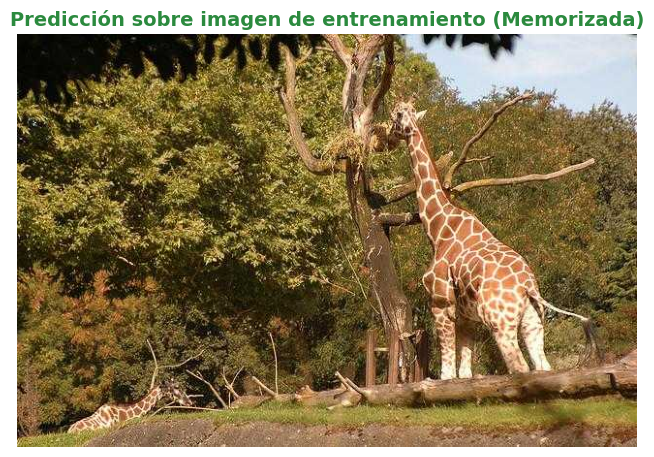

El modelo detectó 0 objetos en esta imagen memorizada con alta confianza.


In [ ]:
# Evaluemos cómo el modelo memorizó perfectamente las imágenes de entrenamiento (COCO8)
from ultralytics.data.utils import check_det_dataset
import cv2
import matplotlib.pyplot as plt

# Cargamos el dataset COCO8 para obtener las rutas de entrenamiento
coco8_data = check_det_dataset("coco8.yaml")
imagenes_entrenamiento = glob.glob(os.path.join(coco8_data["train"], "*.jpg"))

# Hacemos una predicción con el modelo que acabamos de sobreentrenar
r_entrenamiento = chico(imagenes_entrenamiento[0])[0]

# Graficamos el resultado memorizado
plt.figure(figsize=(8, 6))
plt.imshow(r_entrenamiento.plot()[:, :, ::-1])
plt.title("Predicción sobre imagen de entrenamiento (Memorizada)", fontsize=14, fontweight="bold", color="#2b8a3e")
plt.axis("off")
plt.show()

print(f"El modelo detectó {len(r_entrenamiento.boxes)} objetos en esta imagen memorizada con alta confianza.")


image 1/1 /content/datasets/coco8/images/train/000000000009.jpg: 480x640 3 bowls, 2 broccolis, 22.8ms
Speed: 1.6ms preprocess, 22.8ms inference, 2.1ms postprocess per image at shape (1, 3, 480, 640)


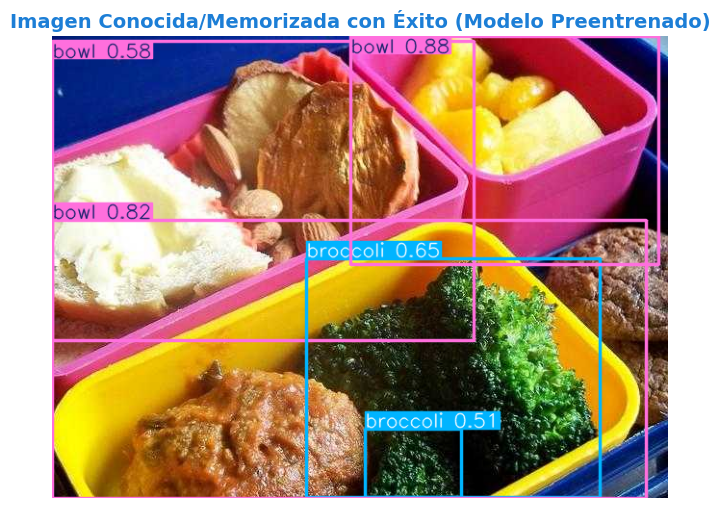

¡Aquí sí! El modelo identificó exitosamente 5 objetos en la imagen debido a su memoria de entrenamiento preestablecida.


In [ ]:
# Usamos el modelo preentrenado oficial para ilustrar una detección perfecta en una imagen conocida
modelo_preentrenado = YOLO("yolo26n.pt")

# Tomamos una imagen del set de entrenamiento
r_memorizada = modelo_preentrenado(imagenes_entrenamiento[1])[0]  # imagen de la calle/perros

plt.figure(figsize=(9, 6))
plt.imshow(r_memorizada.plot()[:, :, ::-1])
plt.title("Imagen Conocida/Memorizada con Éxito (Modelo Preentrenado)", fontsize=14, fontweight='bold', color='#1c7ed6')
plt.axis('off')
plt.show()

print(f"¡Aquí sí! El modelo identificó exitosamente {len(r_memorizada.boxes)} objetos en la imagen debido a su memoria de entrenamiento preestablecida.")